# DSCI 552 — Homework 5

- **Name:** Danmu Agudanmu
- **GitHub Username:** uudam42

In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LassoCV, LinearRegression, RidgeCV
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
SEED = 552
DATA_DIR = Path("../Homework 5 Data")

## Problem 1: Decision Trees as Interpretable Models

### 1(a) Loading the Acute Inflammations data

The file is UTF-16 encoded, tab-separated, and the temperature uses a decimal comma (e.g. `35,9`). The six attributes are temperature and five yes/no symptoms; the two labels are *inflammation of urinary bladder* and *nephritis of renal pelvis origin*. I map yes/no to 1/0.

In [4]:
FEATURES_1 = ["temperature", "nausea", "lumbar_pain", "urine_pushing", "micturition_pains", "burning_urethra"]
LABELS_1 = ["inflammation", "nephritis"]

acute = pd.read_csv(DATA_DIR / "diagnosis.data", sep="\t", header=None,
                    encoding="utf-16", decimal=",", names=FEATURES_1 + LABELS_1)
acute = acute.apply(lambda s: s.str.strip() if s.dtype == object else s)
acute = acute.replace({"yes": 1, "no": 0}).infer_objects()
print(acute.shape)
acute.head()

(120, 8)


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### 1(b) Decision tree on the whole data set

This is a multi-label problem with two binary labels. I use the **label powerset** method: each combination of (inflammation, nephritis) becomes one class, so there are at most 4 classes. I think label powerset is the better choice here (answer to the footnote): the two diseases often occur together (nephritis patients very often also have bladder symptoms), so the labels are correlated. Label powerset keeps that dependence and gives **one** tree with one set of rules, which is easier to interpret than two separate trees from binary relevance.

diagnosis
inflammation only    40
nephritis only       31
none                 30
both                 19
Name: count, dtype: int64

Depth = 4, leaves = 6, training accuracy = 1.000


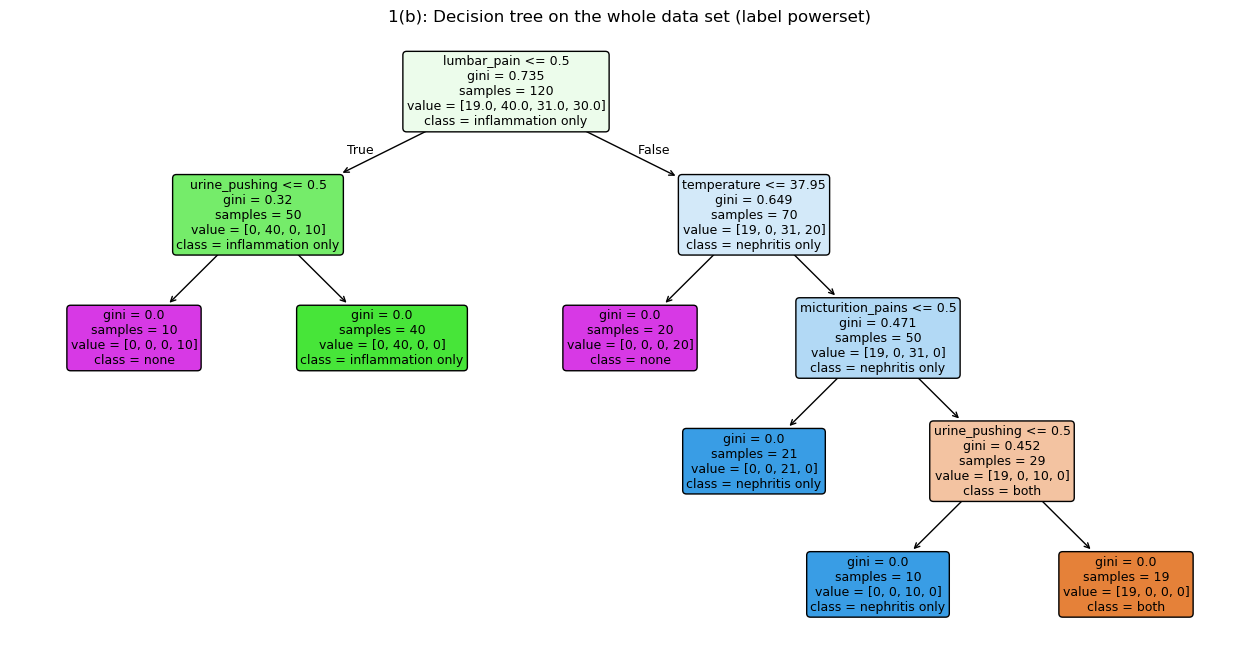

In [6]:
POWERSET = {(0, 0): "none", (1, 0): "inflammation only", (0, 1): "nephritis only", (1, 1): "both"}
X1 = acute[FEATURES_1]
y1 = pd.Series([POWERSET[(a, b)] for a, b in zip(acute["inflammation"], acute["nephritis"])], name="diagnosis")
print(y1.value_counts())

tree_full = DecisionTreeClassifier(random_state=SEED).fit(X1, y1)
print(f"\nDepth = {tree_full.get_depth()}, leaves = {tree_full.get_n_leaves()}, "
      f"training accuracy = {tree_full.score(X1, y1):.3f}")

plt.figure(figsize=(16, 8))
plot_tree(tree_full, feature_names=FEATURES_1, class_names=list(tree_full.classes_),
          filled=True, rounded=True, fontsize=9)
plt.title("1(b): Decision tree on the whole data set (label powerset)")
plt.show()

### 1(c) IF-THEN rules

I adapted the code from the KDnuggets article: walk from the root to every leaf and join the split conditions with AND. Since the symptoms are 0/1, I print `<= 0.5` as `= no` and `> 0.5` as `= yes` to make the rules easier to read.

In [8]:
def get_rules(tree, feature_names, class_names):
    t = tree.tree_
    rules = []

    def cond(name, thr, left):
        if name == "temperature":
            return f"{name} {'<=' if left else '>'} {thr:.2f}"
        return f"{name} = {'no' if left else 'yes'}"

    def recurse(node, path):
        if t.feature[node] != _tree.TREE_UNDEFINED:
            name, thr = feature_names[t.feature[node]], t.threshold[node]
            recurse(t.children_left[node], path + [cond(name, thr, True)])
            recurse(t.children_right[node], path + [cond(name, thr, False)])
        else:
            counts = t.value[node][0]
            label = class_names[np.argmax(counts)]
            n = int(t.n_node_samples[node])
            rules.append(f"IF {' AND '.join(path)} THEN diagnosis = {label}  ({n} samples)")

    recurse(0, [])
    return rules

for i, r in enumerate(get_rules(tree_full, FEATURES_1, tree_full.classes_), 1):
    print(f"Rule {i}: {r}")

Rule 1: IF lumbar_pain = no AND urine_pushing = no THEN diagnosis = none  (10 samples)
Rule 2: IF lumbar_pain = no AND urine_pushing = yes THEN diagnosis = inflammation only  (40 samples)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95 THEN diagnosis = none  (20 samples)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no THEN diagnosis = nephritis only  (21 samples)
Rule 5: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no THEN diagnosis = nephritis only  (10 samples)
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes THEN diagnosis = both  (19 samples)


### 1(d) Cost-complexity pruning

I get the sequence of effective $\alpha$ values from `cost_complexity_pruning_path`, and for each $\alpha$ I compute the 5-fold stratified CV accuracy of the pruned tree. To get a **minimal** tree, I pick the **largest** $\alpha$ whose CV accuracy is within one standard error of the best one.

 alpha  leaves  cv_acc  cv_se
0.0000       6  0.9917 0.0083
0.0982       4  0.8583 0.0250
0.1333       3  0.7667 0.0312
0.1820       2  0.6750 0.0333

Chosen alpha = 0.0000


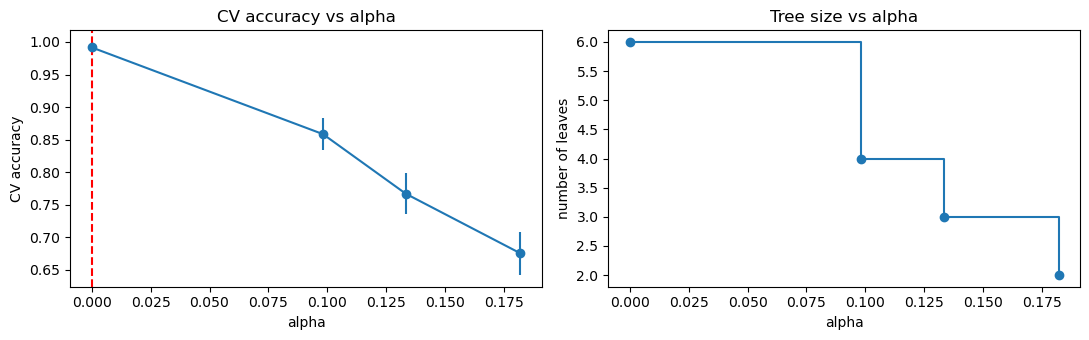

In [10]:
path = tree_full.cost_complexity_pruning_path(X1, y1)
ccp_alphas = path.ccp_alphas[:-1]          # the last alpha prunes the tree down to the root
cv1 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

rows = []
for a in ccp_alphas:
    t = DecisionTreeClassifier(random_state=SEED, ccp_alpha=a)
    scores = cross_val_score(t, X1, y1, cv=cv1)
    rows.append({"alpha": a, "leaves": t.fit(X1, y1).get_n_leaves(),
                 "cv_acc": scores.mean(), "cv_se": scores.std(ddof=1) / np.sqrt(len(scores))})
prune = pd.DataFrame(rows)
print(prune.round(4).to_string(index=False))

best = prune.loc[prune["cv_acc"].idxmax()]
alpha_1se = prune.loc[prune["cv_acc"] >= best["cv_acc"] - best["cv_se"], "alpha"].max()
print(f"\nChosen alpha = {alpha_1se:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].errorbar(prune["alpha"], prune["cv_acc"], yerr=prune["cv_se"], marker="o")
ax[0].axvline(alpha_1se, color="r", ls="--")
ax[0].set(xlabel="alpha", ylabel="CV accuracy", title="CV accuracy vs alpha")
ax[1].step(prune["alpha"], prune["leaves"], where="post", marker="o")
ax[1].set(xlabel="alpha", ylabel="number of leaves", title="Tree size vs alpha")
plt.tight_layout()
plt.show()

Pruned tree: depth = 4, leaves = 6, accuracy on the whole data = 1.000


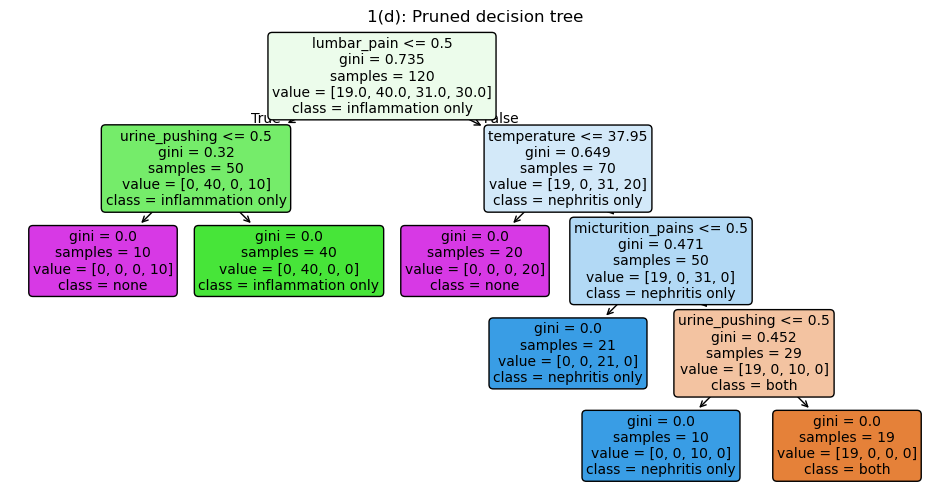

Rule 1: IF lumbar_pain = no AND urine_pushing = no THEN diagnosis = none  (10 samples)
Rule 2: IF lumbar_pain = no AND urine_pushing = yes THEN diagnosis = inflammation only  (40 samples)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95 THEN diagnosis = none  (20 samples)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no THEN diagnosis = nephritis only  (21 samples)
Rule 5: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no THEN diagnosis = nephritis only  (10 samples)
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes THEN diagnosis = both  (19 samples)


In [11]:
tree_pruned = DecisionTreeClassifier(random_state=SEED, ccp_alpha=alpha_1se).fit(X1, y1)
print(f"Pruned tree: depth = {tree_pruned.get_depth()}, leaves = {tree_pruned.get_n_leaves()}, "
      f"accuracy on the whole data = {tree_pruned.score(X1, y1):.3f}")

plt.figure(figsize=(12, 6))
plot_tree(tree_pruned, feature_names=FEATURES_1, class_names=list(tree_pruned.classes_),
          filled=True, rounded=True, fontsize=10)
plt.title("1(d): Pruned decision tree")
plt.show()

for i, r in enumerate(get_rules(tree_pruned, FEATURES_1, tree_pruned.classes_), 1):
    print(f"Rule {i}: {r}")

The CV accuracy is highest for the unpruned tree ($\alpha = 0$, 6 leaves, 99.17%), and it drops a lot as soon as any split is pruned (85.83% with 4 leaves, 76.67% with 3, 67.50% with 2). Even with the one-standard-error rule the chosen $\alpha$ is 0. So the 6-leaf tree is the smallest tree **among the candidate subtrees on the pruning path** that keeps the CV accuracy close to the best. This does not prove that no smaller decision tree exists at all; it is only the best choice among the subtrees I evaluated.

The tree only uses 4 of the 6 attributes (nausea and burning of urethra are never used). Rules 1 and 3 both give *none*, and rules 4 and 5 both give *nephritis only*, so the same tree can be written as a shorter set of rules for the two labels:

1. IF lumbar pain = no THEN inflammation = urine pushing, nephritis = no.
2. IF lumbar pain = yes AND temperature $\le$ 37.95 THEN inflammation = no, nephritis = no.
3. IF lumbar pain = yes AND temperature $>$ 37.95 THEN nephritis = yes, and inflammation = yes only if micturition pains = yes AND urine pushing = yes.

These rules give exactly the same predictions as the 6-leaf tree, and in my opinion they give the best balance of accuracy and interpretability among the pruning candidates.

## Problem 2: The LASSO and Boosting for Regression

### 2(a) Loading the Communities and Crime data

The column names are read from the `@attribute` lines of `communities.names`. Missing values are coded as `?`. The first 1495 rows are the training set and the remaining 499 rows are the test set.

In [14]:
cols = [line.split()[1] for line in open(DATA_DIR / "communities.names") if line.startswith("@attribute")]
crime = pd.read_csv(DATA_DIR / "communities.data", header=None, names=cols, na_values="?")
print(crime.shape)

TARGET = "ViolentCrimesPerPop"
N_TRAIN = 1495

(1994, 128)


### 2(b) Non-predictive features and missing values

The data description says the first 5 attributes (`state`, `county`, `community`, `communityname`, `fold`) are not predictive, so I drop them. That leaves 122 predictive features and the target.

In [16]:
NON_PREDICTIVE = ["state", "county", "community", "communityname", "fold"]
crime = crime.drop(columns=NON_PREDICTIVE)
FEATS_2 = [c for c in crime.columns if c != TARGET]
print(f"{len(FEATS_2)} features")

missing = crime.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(f"\n{len(missing)} columns have missing values:")
print(missing.to_string())

122 features

23 columns have missing values:
PctPolicBlack           1675
PctPolicHisp            1675
LemasGangUnitDeploy     1675
LemasPctPolicOnPatr     1675
PolicOperBudg           1675
PolicCars               1675
PolicAveOTWorked        1675
NumKindsDrugsSeiz       1675
OfficAssgnDrugUnits     1675
PctPolicMinor           1675
PctPolicAsian           1675
PolicBudgPerPop         1675
LemasSwornFT            1675
PctPolicWhite           1675
RacialMatchCommPol      1675
PolicPerPop             1675
PolicReqPerOffic        1675
LemasTotReqPerPop       1675
LemasTotalReq           1675
LemasSwFTFieldPerPop    1675
LemasSwFTFieldOps       1675
LemasSwFTPerPop         1675
OtherPerCap                1


22 of the features are missing for about 84% of the communities (police statistics from LEMAS), and `OtherPerCap` is missing once. I use **median imputation**: each missing value is replaced by the median of that feature in the training set (fitted on the training set only, so no test information is used). The median is less sensitive to the skewed distributions than the mean.

In [18]:
train, test = crime.iloc[:N_TRAIN], crime.iloc[N_TRAIN:]
imputer = SimpleImputer(strategy="median").fit(train[FEATS_2])
X_train = pd.DataFrame(imputer.transform(train[FEATS_2]), columns=FEATS_2)
X_test = pd.DataFrame(imputer.transform(test[FEATS_2]), columns=FEATS_2)
y_train, y_test = train[TARGET].to_numpy(), test[TARGET].to_numpy()
X_all = pd.concat([X_train, X_test], ignore_index=True)    # imputed full data, used for 2(c)-(e)
y_all = np.r_[y_train, y_test]
print(X_train.shape, X_test.shape, "missing left:", X_all.isna().sum().sum())

(1495, 122) (499, 122) missing left: 0


### 2(c) Correlation matrix

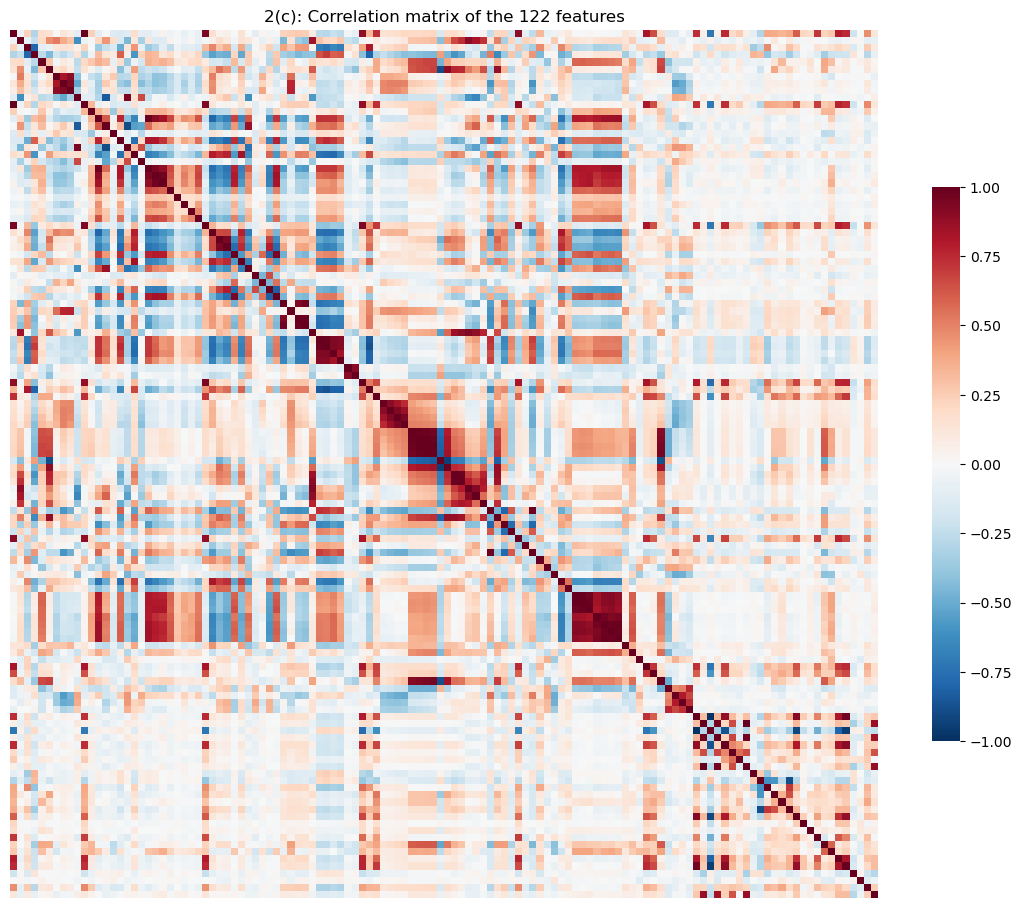

Number of feature pairs with |r| > 0.9: 58
LemasSwFTPerPop  PolicPerPop      1.000
PctRecImmig8     PctRecImmig10    0.996
OwnOccLowQuart   OwnOccMedVal     0.994
PctRecImmig5     PctRecImmig8     0.993
population       numbUrban        0.993


In [20]:
corr = X_all.corr()
plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, square=True, xticklabels=False, yticklabels=False,
            cbar_kws={"shrink": 0.6})
plt.title("2(c): Correlation matrix of the 122 features")
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("Number of feature pairs with |r| > 0.9:", (upper.abs() > 0.9).sum())
print(upper.abs().sort_values(ascending=False).head(5).round(3).to_string())

Many features are strongly correlated (58 pairs with $|r| > 0.9$). Most of them are different versions of the same quantity, e.g. counts vs. population (`population`, `numbUrban`), the immigration percentages over different years, or the housing value quartiles. The police (LEMAS) features are also highly correlated with each other. This collinearity is a reason to use regularization (ridge/LASSO) or PCR.

### 2(d) Coefficient of Variation

$CV = s / m$, with the sample standard deviation ($ddof = 1$) and the sample mean of each feature.

In [23]:
cv_feat = (X_all.std(ddof=1) / X_all.mean()).sort_values(ascending=False).rename("CV")
cv_feat.round(3).to_frame().T

,PctPolicAsian,NumStreet,NumInShelters,NumIlleg,NumImmig,LemasPctOfficDrugUn,NumUnderPov,population,LemasSwornFT,numbUrban,...,LemasSwFTFieldPerPop,agePct12t29,PctSpeakEnglOnly,PctHousOccup,PolicReqPerOffic,NumKindsDrugsSeiz,RacialMatchCommPol,LemasPctPolicOnPatr,PctPolicWhite,LemasSwFTFieldOps
CV,5.448,4.408,3.485,2.994,2.9,2.555,2.305,2.204,2.081,2.002,...,0.294,0.291,0.289,0.27,0.262,0.143,0.127,0.118,0.118,0.058


### 2(e) The $\lfloor\sqrt{128}\rfloor = 11$ features with the highest CV

11 ['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'LemasSwornFT', 'numbUrban', 'HousVacant']


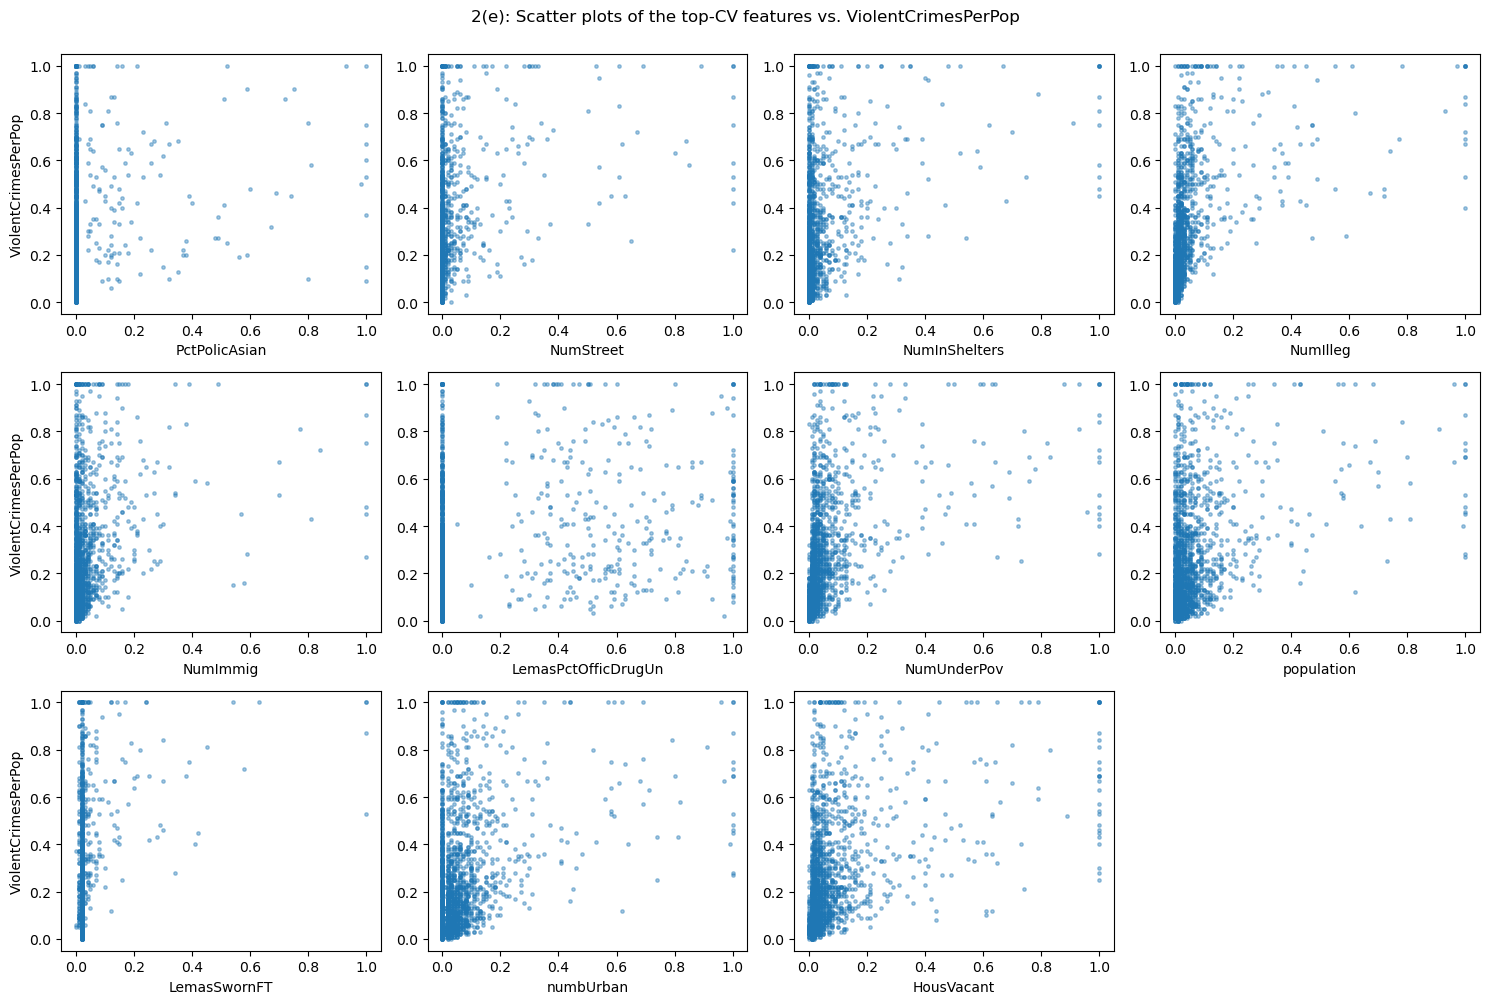

In [25]:
k = int(np.floor(np.sqrt(128)))
top_cv = cv_feat.index[:k].tolist()
print(k, top_cv)

fig, axes = plt.subplots(3, 4, figsize=(15, 10))
for ax, f in zip(axes.ravel(), top_cv):
    ax.scatter(X_all[f], y_all, s=6, alpha=0.4)
    ax.set(xlabel=f, ylabel=TARGET if ax in axes[:, 0] else "")
axes.ravel()[-1].axis("off")
fig.suptitle("2(e): Scatter plots of the top-CV features vs. ViolentCrimesPerPop", y=1.0)
plt.tight_layout()
plt.show()

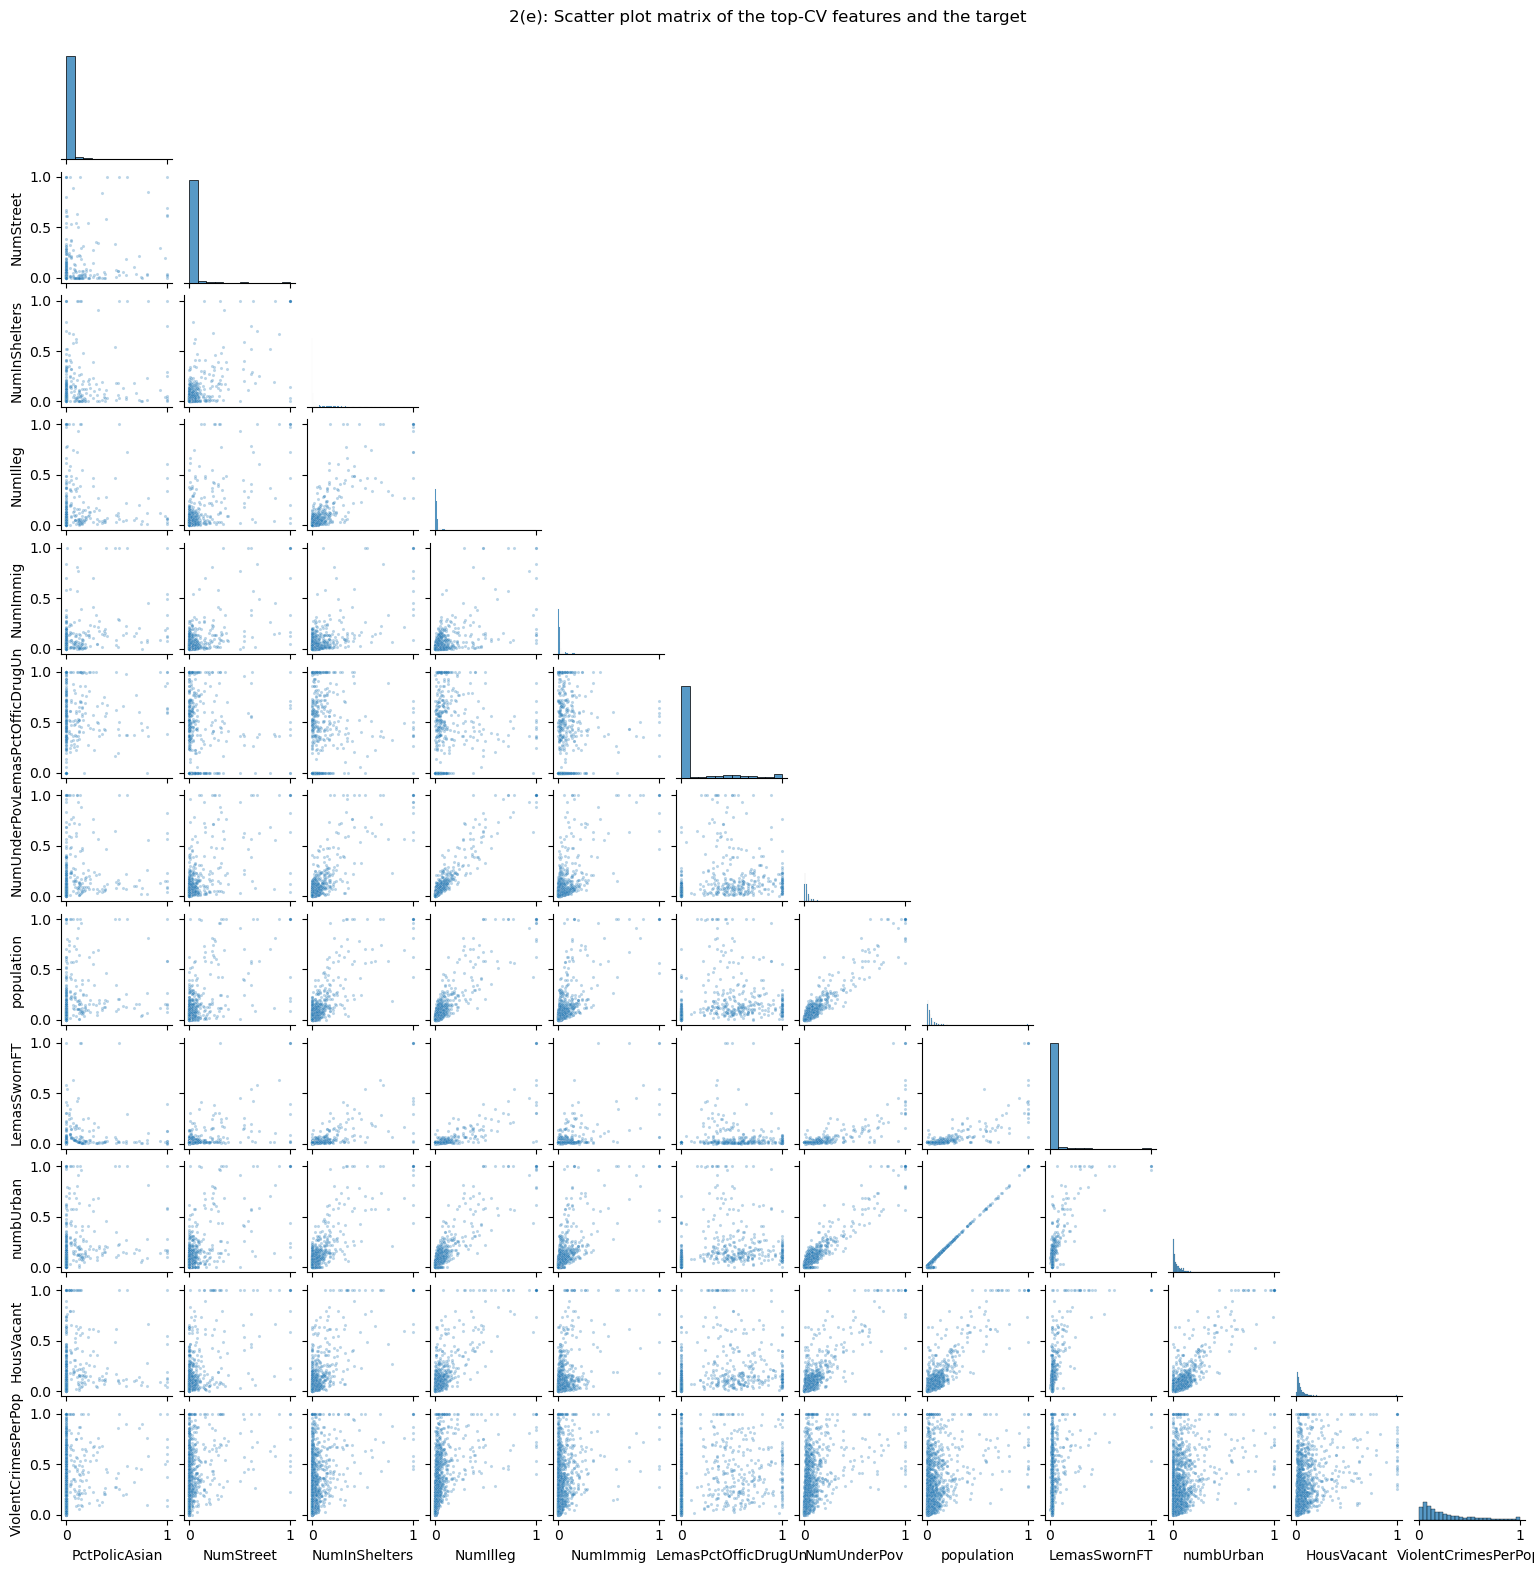

In [26]:
sns.pairplot(pd.concat([X_all[top_cv], pd.Series(y_all, name=TARGET)], axis=1),
             plot_kws={"s": 5, "alpha": 0.3}, corner=True, height=1.3)
plt.suptitle("2(e): Scatter plot matrix of the top-CV features and the target", y=1.01)
plt.show()

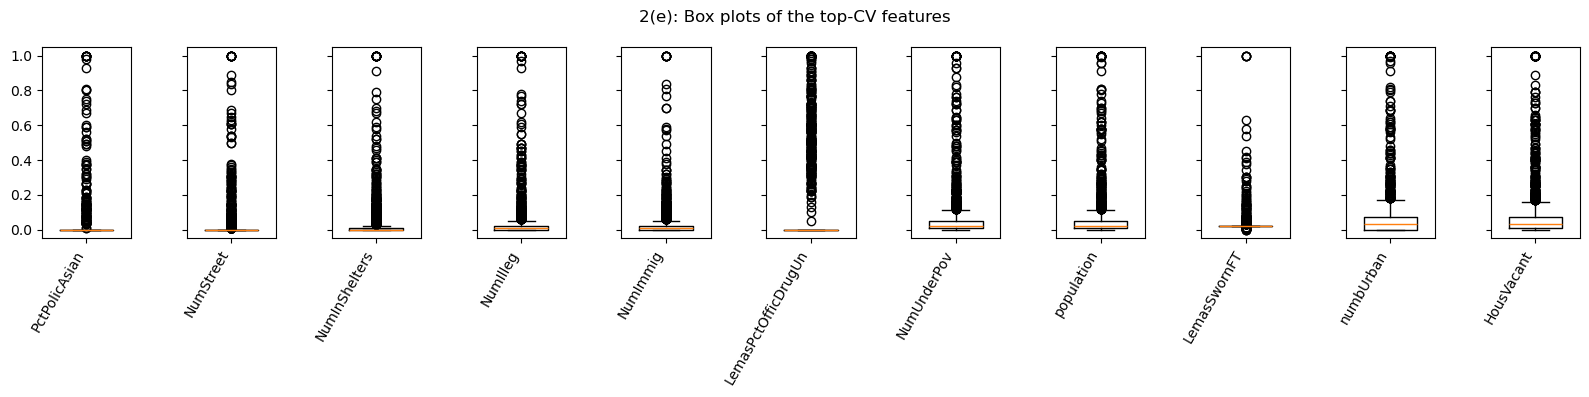

In [27]:
fig, axes = plt.subplots(1, k, figsize=(16, 4), sharey=True)
for ax, f in zip(axes, top_cv):
    ax.boxplot(X_all[f], widths=0.6)
    ax.set_xticks([1], [f], rotation=60, ha="right")
fig.suptitle("2(e): Box plots of the top-CV features")
plt.tight_layout()
plt.show()

Most of the top-CV features are counts (`NumStreet`, `NumInShelters`, `NumIlleg`, `NumImmig`, `NumUnderPov`, `population`, ...). They have a large CV because most communities are small, so the values are close to 0 with a few very large outliers (see the box plots). `PctPolicAsian` is the imputed median for the 84% of communities without police data, and `LemasPctOfficDrugUn` is 0 for most communities.

**No, we cannot conclude significance from the scatter plots alone.** Some plots show a weak positive trend with the target (e.g. `NumIlleg`, `NumUnderPov`), but the points are squeezed near 0 and the spread is large. A scatter plot only shows the marginal relation of one feature with the target; it does not account for the other (highly correlated) features, and it does not give a standard error or p-value. Significance needs a fitted model and a test. Also, a high CV does not mean a feature is important for prediction.

### 2(f) Linear model (least squares)

I report the test error as the test MSE.

In [30]:
def test_mse(model):
    return mean_squared_error(y_test, model.predict(X_test))

results = {}
ols = LinearRegression().fit(X_train, y_train)
results["Least squares"] = test_mse(ols)
print(f"Least squares test MSE = {results['Least squares']:.5f}")

Least squares test MSE = 0.01797


### 2(g) Ridge regression, $\lambda$ chosen by 10-fold CV

In [ ]:
cv10 = KFold(n_splits=10, shuffle=True, random_state=SEED)
lambdas = np.logspace(-4, 3, 100)

ridge = RidgeCV(alphas=lambdas, cv=cv10, scoring="neg_mean_squared_error").fit(X_train, y_train)
results["Ridge"] = test_mse(ridge)
print(f"lambda = {ridge.alpha_:.4f}, ridge test MSE = {results['Ridge']:.5f}")

### 2(h) LASSO, $\lambda$ chosen by 10-fold CV

First with the features as given (already normalized to $[0, 1]$), then with standardized features (mean 0, variance 1, scaler fitted inside the pipeline on the training data).

In [ ]:
lasso = LassoCV(cv=cv10, n_alphas=100, max_iter=50000, random_state=SEED).fit(X_train, y_train)
results["LASSO"] = test_mse(lasso)
sel = pd.Series(lasso.coef_, index=FEATS_2)
sel = sel[sel != 0].sort_values(key=np.abs, ascending=False)
print(f"lambda = {lasso.alpha_:.6f}, LASSO test MSE = {results['LASSO']:.5f}")
print(f"{len(sel)} variables selected:")
print(sel.round(4).to_string())

In [ ]:
lasso_std = Pipeline([("scale", StandardScaler()),
                      ("lasso", LassoCV(cv=cv10, n_alphas=100, max_iter=50000, random_state=SEED))])
lasso_std.fit(X_train, y_train)
results["LASSO (standardized)"] = test_mse(lasso_std)
sel_std = pd.Series(lasso_std["lasso"].coef_, index=FEATS_2)
sel_std = sel_std[sel_std != 0].sort_values(key=np.abs, ascending=False)
print(f"lambda = {lasso_std['lasso'].alpha_:.6f}, standardized LASSO test MSE = {results['LASSO (standardized)']:.5f}")
print(f"{len(sel_std)} variables selected:")
print(sel_std.round(4).to_string())

LASSO (raw features) has test MSE 0.01769 and keeps 79 of the 122 variables. With standardized features the test MSE is 0.01773 and 76 variables are kept, mostly the same ones (`racepctblack`, `agePct12t29`, `PctPersDenseHous`, `PctKids2Par`, `MedRent`, ...). The two test errors are almost the same. This is expected, because the features are already normalized to $[0, 1]$, so they are on similar scales and standardizing changes the penalty only a little. The coefficients have different sizes because they are on different scales (per unit vs. per standard deviation).

### 2(i) Principal Components Regression, $M$ chosen by 10-fold CV

Pipeline: standardize, PCA with $M$ components, least squares. I try $M = 1, \dots, 122$.

In [ ]:
pcr = Pipeline([("scale", StandardScaler()), ("pca", PCA()), ("ols", LinearRegression())])
pcr_cv = GridSearchCV(pcr, {"pca__n_components": range(1, len(FEATS_2) + 1)}, cv=cv10,
                      scoring="neg_mean_squared_error", n_jobs=-1).fit(X_train, y_train)
best_M = pcr_cv.best_params_["pca__n_components"]
results["PCR"] = test_mse(pcr_cv.best_estimator_)
print(f"M = {best_M}, PCR test MSE = {results['PCR']:.5f}")

plt.figure(figsize=(7, 3.5))
plt.plot(range(1, len(FEATS_2) + 1), -pcr_cv.cv_results_["mean_test_score"])
plt.axvline(best_M, color="r", ls="--", label=f"M = {best_M}")
plt.xlabel("M (number of components)")
plt.ylabel("10-fold CV MSE")
plt.title("2(i): PCR cross-validation")
plt.legend()
plt.show()

### 2(j) L1-penalized gradient boosting tree (XGBoost)

In XGBoost the L1 penalty is `reg_alpha` ($\alpha$), which penalizes the absolute values of the leaf weights. I fix the other hyperparameters at reasonable values (300 trees, learning rate 0.05, depth 3, subsampling 0.8) and choose $\alpha$ by 10-fold CV.

In [ ]:
xgb = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8,
                   colsample_bytree=0.8, random_state=SEED, n_jobs=1)
alphas_xgb = [0, 0.001, 0.01, 0.05, 0.1, 0.5, 1, 2, 5, 10]
xgb_cv = GridSearchCV(xgb, {"reg_alpha": alphas_xgb}, cv=cv10,
                      scoring="neg_mean_squared_error", n_jobs=-1).fit(X_train, y_train)
best_alpha = xgb_cv.best_params_["reg_alpha"]
results["XGBoost (L1)"] = test_mse(xgb_cv.best_estimator_)
print(pd.Series(-xgb_cv.cv_results_["mean_test_score"], index=alphas_xgb, name="CV MSE").round(5).to_frame().T)
print(f"\nalpha = {best_alpha}, XGBoost test MSE = {results['XGBoost (L1)']:.5f}")

### Summary of test errors

In [ ]:
pd.Series(results, name="test MSE").round(5).to_frame()

The linear models all have a similar test MSE (about 0.018). Ridge and LASSO are a little better than plain least squares because they shrink the coefficients of the many correlated features. PCR is the worst of the linear methods; it needs $M = 97$ components, so the target is not explained by only a few top principal components. The L1-penalized boosting tree with $\alpha = 0.5$ has the lowest test MSE (0.01603), probably because the trees can capture non-linear effects and interactions that the linear models miss.